# EchoNext SHD: preprocessing + multimodal TCN (PyTorch)

Notebook based on Ajadi et al., *Multimodal Deep Learning for Structural Heart Disease Prediction from ECG and Clinical Data* and the official EchoNext dataset.

Pipeline: inspect metadata → load official preprocessed ECG/tabular arrays → align labels → TCN ECG encoder + MLP tabular encoder → adaptive gated late fusion → weighted BCE training → test metrics.

**Reproduction note:** the paper describes this architecture and training protocol but does not publish every layer width/kernel/gating dimension. The architecture dimensions below are implementation choices, not claimed to be the original authors' exact code. This is for research/education, not clinical diagnosis.

## 1. Download the dataset

Get **EchoNext v1.1.1** from PhysioNet: https://physionet.org/content/echonext/1.1.1/

PhysioNet requires a registered account and acceptance/signature of its Data Use Agreement. After approval, download and extract the files.

Expected folder:

```text
project/
  data/
    EchoNext_metadata_100k.csv
    EchoNext_train_waveforms.npy
    EchoNext_val_waveforms.npy
    EchoNext_test_waveforms.npy
    EchoNext_train_tabular_features.npy
    EchoNext_val_tabular_features.npy
    EchoNext_test_tabular_features.npy
  EchoNext_TCN_Preprocessing_Training.ipynb
```

The released waveform arrays are 10-second 12-lead ECGs sampled at 250 Hz (2500 samples), usually shaped `(N, 1, 2500, 12)`. Tabular arrays have seven columns: sex, ventricular rate, atrial rate, PR interval, QRS duration, corrected QT, age.

In [ ]:
%pip install -q numpy pandas matplotlib scikit-learn torch

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.randn(3000, 3000, device="cuda")
    y = torch.randn(3000, 3000, device="cuda")
    z = x @ y

    print("GPU computation successful!")
    print(z.device)

PyTorch: 2.13.0+cu130
CUDA version: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
GPU computation successful!
cuda:0


In [2]:
from pathlib import Path
import copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    f1_score, balanced_accuracy_score, confusion_matrix, classification_report)

DATA_DIR = Path(".")  # edit if your data folder is elsewhere
META_FILE = DATA_DIR / "echonext_metadata_100k.csv"
WAVE = {s: DATA_DIR / f"EchoNext_{s}_waveforms.npy" for s in ["train","val","test"]}
TAB  = {s: DATA_DIR / f"EchoNext_{s}_tabular_features.npy" for s in ["train","val","test"]}
TARGET = "shd_moderate_or_greater_flag"
TABULAR_COLUMNS = ["sex","ventricular_rate","atrial_rate","pr_interval","qrs_duration","qt_corrected","age_at_ecg"]

SEED, BATCH_SIZE, EPOCHS = 1, 8, 60
LR, WEIGHT_DECAY, PATIENCE = 3e-4, 1e-4, 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available(): print(torch.cuda.get_device_name(0))

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(SEED)

Device: cuda
NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Inspect metadata and labels

The official metadata includes a `split` column. Keep the official train/validation/test split; do not randomly split individual ECG rows, because multiple ECGs may belong to the same patient.

In [3]:
if not META_FILE.exists():
    raise FileNotFoundError(f"Metadata not found: {META_FILE}. Download EchoNext and place it in DATA_DIR.")
metadata = pd.read_csv(META_FILE)
print(metadata.shape)
print(metadata.columns.tolist())
print(metadata["split"].value_counts(dropna=False))
if TARGET not in metadata or "split" not in metadata:
    raise ValueError(f"Metadata must contain 'split' and '{TARGET}'.")
print(pd.crosstab(metadata["split"], metadata[TARGET], margins=True))

(100000, 39)
['Unnamed: 0', 'ecg_key', 'patient_key', 'age_at_ecg', 'sex', 'acquisition_year', 'location_setting', 'race_ethnicity', 'most_recent_ecg', 'ventricular_rate', 'atrial_rate', 'pr_interval', 'qrs_duration', 'qt_corrected', 'lvef_lte_45_flag', 'lvwt_gte_13_flag', 'aortic_stenosis_moderate_or_greater_flag', 'aortic_regurgitation_moderate_or_greater_flag', 'mitral_regurgitation_moderate_or_greater_flag', 'tricuspid_regurgitation_moderate_or_greater_flag', 'pulmonary_regurgitation_moderate_or_greater_flag', 'rv_systolic_dysfunction_moderate_or_greater_flag', 'pericardial_effusion_moderate_large_flag', 'pasp_gte_45_flag', 'tr_max_gte_32_flag', 'shd_moderate_or_greater_flag', 'aortic_stenosis_value', 'aortic_regurgitation_value', 'mitral_regurgitation_value', 'tricuspid_regurgitation_value', 'pulmonary_regurgitation_value', 'rv_systolic_function_value', 'pericardial_effusion_value', 'ivs_measurement', 'lvpw_measurement', 'pasp_value', 'tr_max_velocity_value', 'lvef_value', 'split'

| Split      | Records | Percentage |
|------------|--------:|-----------:|
| Train      | 72,475  | 72.48%     |
| Validation | 4,626   | 4.63%      |
| Test       | 5,442   | 5.44%      |
| No split   | 17,457  | 17.46%     |
| **Total**  | **100,000** | **100%** |

## 3. Load official preprocessed files

**Important:** the dataset's distributed `.npy` files are already preprocessed. PhysioNet documents that ECG waveforms were median-filtered per lead, clipped at the 0.1st/99.9th percentiles, then normalized using dataset-wide mean and standard deviation. Tabular continuous features are standardized; missing values are median-imputed except atrial rate and PR interval, which are set to zero; sex is binary encoded.

Do not apply a second normalization/filtering pass to these arrays.

In [4]:
def load_split(split):
    meta = metadata.loc[metadata["split"].astype(str).str.lower().eq(split)].reset_index(drop=True)
    for p in (WAVE[split], TAB[split]):
        if not p.exists(): raise FileNotFoundError(f"Missing {p}")
    x_ecg = np.load(WAVE[split], mmap_mode="r")
    x_tab = np.load(TAB[split], mmap_mode="r")
    y = meta[TARGET].to_numpy(dtype=np.float32)
    print(split, "ECG", x_ecg.shape, "tabular", x_tab.shape, "metadata", meta.shape, "labels", y.shape)
    if not (len(x_ecg) == len(x_tab) == len(meta)):
        raise ValueError("Row mismatch: metadata split and corresponding .npy arrays must align.")
    if not np.isfinite(np.asarray(x_tab)).all(): raise ValueError("Tabular data has NaN/Inf.")
    return x_ecg, x_tab, y, meta

train_ecg, train_tab, y_train, train_meta = load_split("train")
val_ecg, val_tab, y_val, val_meta = load_split("val")
test_ecg, test_tab, y_test, test_meta = load_split("test")

train ECG (72475, 1, 2500, 12) tabular (72475, 7) metadata (72475, 39) labels (72475,)
val ECG (4626, 1, 2500, 12) tabular (4626, 7) metadata (4626, 39) labels (4626,)
test ECG (5442, 1, 2500, 12) tabular (5442, 7) metadata (5442, 39) labels (5442,)


Single ECG shape: (2500, 12)


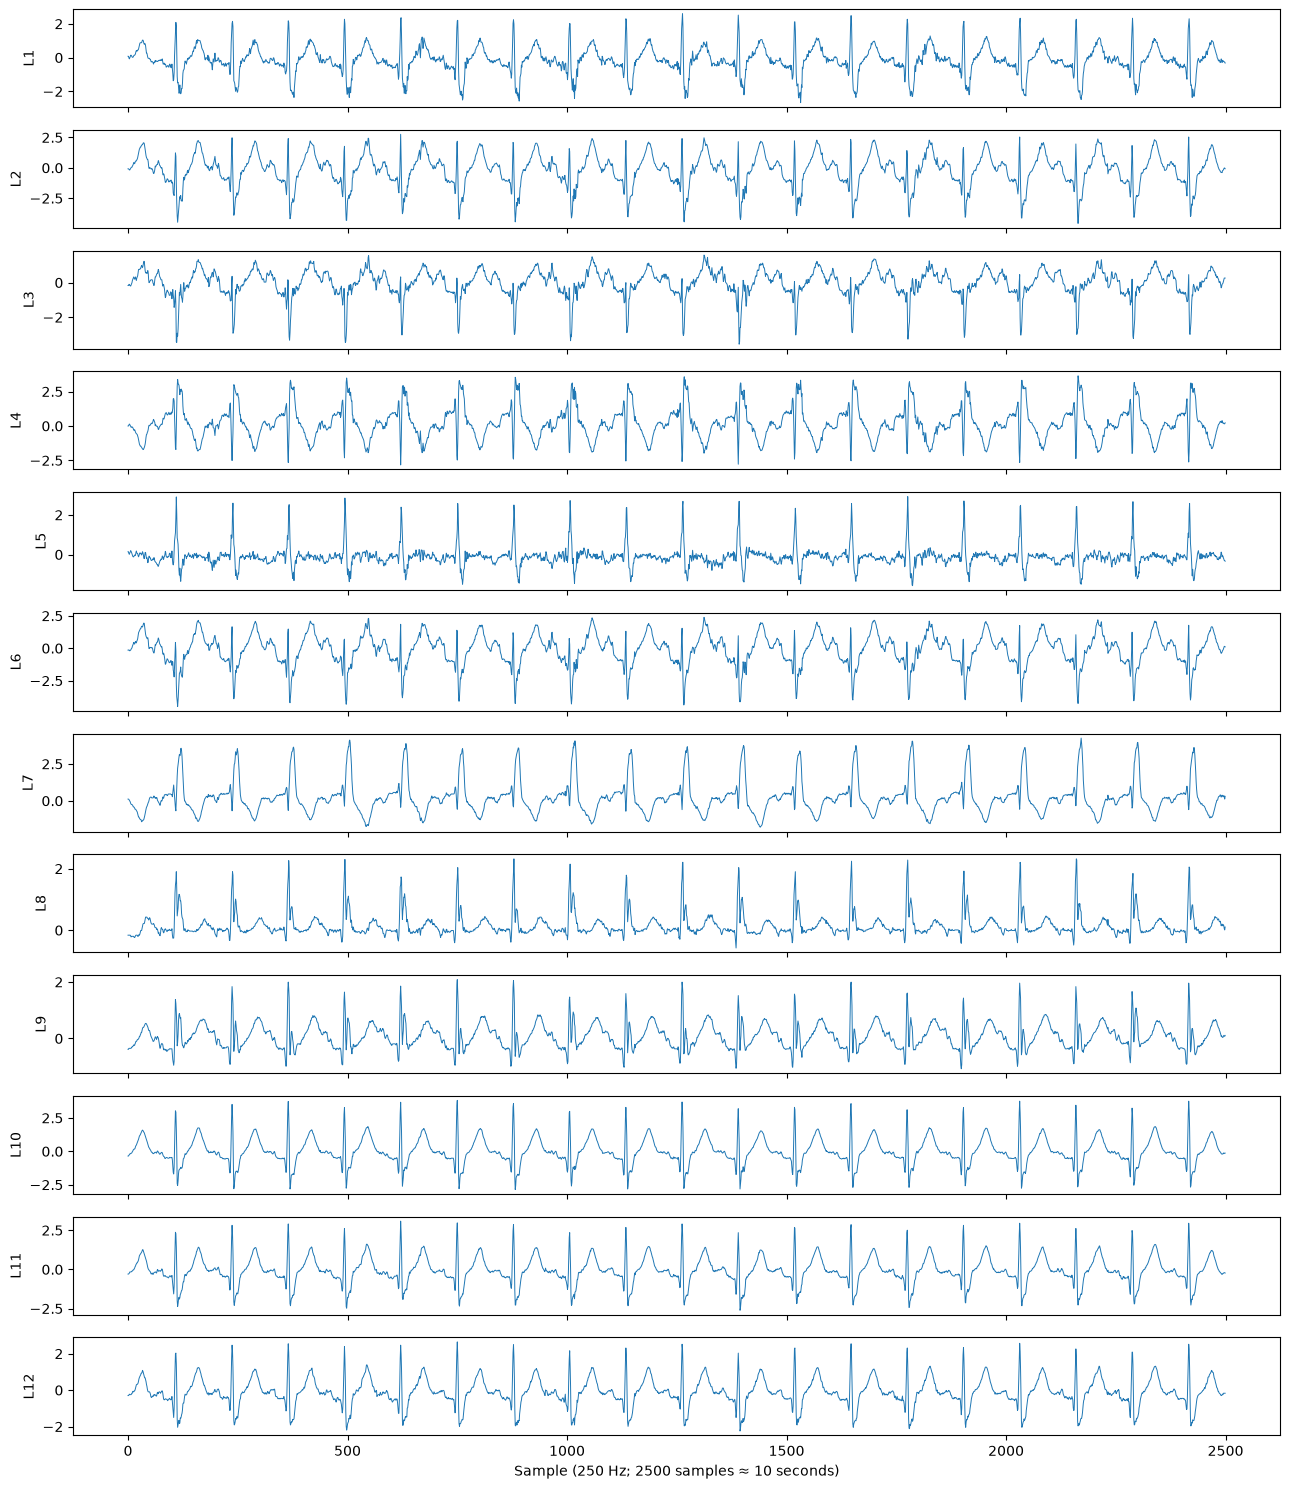

In [5]:
# Plot one ECG to verify the waveform is loaded correctly.
sample = np.squeeze(np.asarray(train_ecg[0]))
print("Single ECG shape:", sample.shape)
if sample.shape == (2500, 12): signal = sample
elif sample.shape == (12, 2500): signal = sample.T
else: raise ValueError(f"Unexpected ECG sample shape: {sample.shape}")
fig, ax = plt.subplots(12, 1, figsize=(13, 15), sharex=True)
for i in range(12):
    ax[i].plot(signal[:, i], lw=.7); ax[i].set_ylabel(f"L{i+1}")
ax[-1].set_xlabel("Sample (250 Hz; 2500 samples ≈ 10 seconds)")
plt.tight_layout()

## 4. Prepare tensors

TCN input convention is `(batch, channels, time)` = `(B, 12, 2500)`. The released array is commonly `(N, 1, 2500, 12)`, so we remove the singleton dimension and transpose time/leads.

In [ ]:
def channel_first(a):
    a = np.asarray(a, dtype=np.float32)
    if a.ndim == 4 and a.shape[1] == 1: a = a[:, 0]
    if a.ndim != 3: raise ValueError(f"Unexpected ECG shape {a.shape}")
    if a.shape[1:] == (2500, 12): a = a.transpose(0, 2, 1)
    elif a.shape[1:] != (12, 2500): raise ValueError(f"Expected N*2500*12 or N*12*2500, got {a.shape}")
    return np.ascontiguousarray(a)

class ECGDataset(Dataset):
    def __init__(self, ecg, tab, y):
        self.ecg, self.tab, self.y = channel_first(ecg), np.asarray(tab, np.float32), np.asarray(y, np.float32)
        assert len(self.ecg) == len(self.tab) == len(self.y)
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return (torch.from_numpy(self.ecg[i]), torch.from_numpy(self.tab[i]),
                torch.tensor(self.y[i], dtype=torch.float32))

train_ds, val_ds, test_ds = (ECGDataset(*z) for z in [
    (train_ecg, train_tab, y_train), (val_ecg, val_tab, y_val), (test_ecg, test_tab, y_test)])
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
a,b,c = next(iter(train_loader))
print(a.shape, b.shape, c.shape)

torch.Size([8, 12, 2500]) torch.Size([8, 7]) torch.Size([8])


## 5. TCN encoder + tabular MLP + gated late fusion

A TCN uses dilated temporal convolutions to cover longer time ranges. The ECG encoder and tabular MLP produce equal-sized embeddings. A gating network computes two softmax weights; the weighted embeddings are fused and passed to a binary classifier.

In [7]:
class Chomp1d(nn.Module):
    def __init__(self, n): super().__init__(); self.n=n
    def forward(self, x): return x[:, :, :-self.n] if self.n else x

class TemporalBlock(nn.Module):
    def __init__(self, cin, cout, k=7, dilation=1, dropout=.15):
        super().__init__(); pad=(k-1)*dilation
        self.net=nn.Sequential(
            nn.Conv1d(cin,cout,k,padding=pad,dilation=dilation), Chomp1d(pad),
            nn.BatchNorm1d(cout), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(cout,cout,k,padding=pad,dilation=dilation), Chomp1d(pad),
            nn.BatchNorm1d(cout), nn.ReLU(), nn.Dropout(dropout))
        self.skip=nn.Conv1d(cin,cout,1) if cin!=cout else nn.Identity()
        self.act=nn.ReLU()
    def forward(self,x): return self.act(self.net(x)+self.skip(x))

class TCNEncoder(nn.Module):
    def __init__(self, emb=128):
        super().__init__()
        widths=[32,64,96,128]; layers=[]; cin=12
        for i,cout in enumerate(widths):
            layers.append(TemporalBlock(cin,cout,dilation=2**i)); cin=cout
        self.tcn=nn.Sequential(*layers)
        self.head=nn.Sequential(nn.AdaptiveAvgPool1d(1),nn.Flatten(),
                                 nn.Linear(128,emb),nn.ReLU(),nn.Dropout(.2))
    def forward(self,x): return self.head(self.tcn(x))

class TabularEncoder(nn.Module):
    def __init__(self, emb=128):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(7,64),nn.ReLU(),nn.Dropout(.2),
                               nn.Linear(64,emb),nn.ReLU(),nn.Dropout(.2))
    def forward(self,x): return self.net(x)

class MultimodalTCN(nn.Module):
    def __init__(self, emb=128):
        super().__init__()
        self.ecg_encoder=TCNEncoder(emb)
        self.tab_encoder=TabularEncoder(emb)
        self.gate=nn.Sequential(nn.Linear(2*emb,64),nn.ReLU(),nn.Linear(64,2))
        self.classifier=nn.Sequential(nn.Linear(emb,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,1))
    def forward(self,ecg,tab,return_gate=False):
        ze,zt=self.ecg_encoder(ecg),self.tab_encoder(tab)
        w=torch.softmax(self.gate(torch.cat([ze,zt],dim=1)),dim=1)
        fused=w[:,0:1]*ze+w[:,1:2]*zt
        logits=self.classifier(fused).squeeze(1)
        return (logits,w) if return_gate else logits

model=MultimodalTCN().to(device)
with torch.no_grad():
    logits, gates=model(a.to(device),b.to(device),True)
print("logits",logits.shape,"gates",gates.shape,"gate sums",gates.sum(1))

logits torch.Size([8]) gates torch.Size([8, 2]) gate sums tensor([1., 1., 1., 1., 1., 1., 1., 1.], device='cuda:0')


## 6. Loss and optimizer

The paper uses binary cross-entropy with logits and a positive-class weighting factor calculated from the training data, AdamW (`lr=3e-4`, `weight_decay=1e-4`), and cosine learning-rate scheduling with warm-up.

In [8]:
n_pos=float((y_train==1).sum()); n_neg=float((y_train==0).sum())
if n_pos == 0: raise ValueError("No positive SHD examples in training split.")
pos_weight=torch.tensor([n_neg/n_pos],dtype=torch.float32,device=device)
criterion=nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)

def lr_lambda(epoch):
    warmup=3
    if epoch < warmup: return (epoch+1)/warmup
    progress=(epoch-warmup)/max(1,EPOCHS-warmup)
    return .5*(1+np.cos(np.pi*progress))
scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_lambda)
print("positive:",n_pos,"negative:",n_neg,"pos_weight:",pos_weight.item())

positive: 37958.0 negative: 34517.0 pos_weight: 0.9093471765518188


## 7. Train with validation-AUC checkpointing and early stopping

The paper reports 60 epochs, early stopping on validation AUC, and checkpoint selection by highest validation AUC. It reports three random seeds. Start with one seed first; repeat with seeds 1, 2, and 3 after confirming the pipeline works.

The paper used batch size 64. This notebook defaults to 8 to reduce GPU-memory requirements; increase it if your GPU permits.

In [9]:
def predict(model, loader):
    model.eval(); ys=[]; ps=[]; loss_sum=0; n=0
    with torch.no_grad():
        for ecg,tab,y in loader:
            ecg,tab,y=ecg.to(device),tab.to(device),y.to(device)
            out=model(ecg,tab); loss=criterion(out,y)
            ys.append(y.cpu().numpy()); ps.append(torch.sigmoid(out).cpu().numpy())
            loss_sum += loss.item()*len(y); n += len(y)
    return np.concatenate(ys),np.concatenate(ps),loss_sum/max(n,1)

best_auc=-1; best_state=None; patience_count=0; history=[]
for epoch in range(EPOCHS):
    model.train(); total=0; seen=0
    for ecg,tab,y in train_loader:
        ecg,tab,y=ecg.to(device),tab.to(device),y.to(device)
        optimizer.zero_grad(set_to_none=True)
        out=model(ecg,tab); loss=criterion(out,y)
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0)
        optimizer.step(); total += loss.item()*len(y); seen += len(y)
    scheduler.step()
    vy,vp,vloss=predict(model,val_loader)
    vauc=roc_auc_score(vy,vp) if len(np.unique(vy))==2 else float("nan")
    history.append([epoch+1,total/seen,vloss,vauc])
    print(f"Epoch {epoch+1:02d}: train loss={total/seen:.4f}, val loss={vloss:.4f}, val AUC={vauc:.4f}")
    if vauc > best_auc:
        best_auc=vauc; best_state=copy.deepcopy(model.state_dict())
        torch.save(best_state,"best_echonext_multimodal_tcn.pt"); patience_count=0
    else:
        patience_count += 1
    if patience_count >= PATIENCE:
        print("Early stopping. Best validation AUC:",best_auc); break

if best_state is None: raise RuntimeError("No valid checkpoint.")
model.load_state_dict(best_state)
hist=pd.DataFrame(history,columns=["epoch","train_loss","val_loss","val_auc"])

Epoch 01: train loss=0.5412, val loss=0.4869, val AUC=0.8183
Epoch 02: train loss=0.5178, val loss=0.5039, val AUC=0.8181
Epoch 03: train loss=0.5053, val loss=0.4851, val AUC=0.8227
Epoch 04: train loss=0.4934, val loss=0.4912, val AUC=0.8280
Epoch 05: train loss=0.4852, val loss=0.4882, val AUC=0.8265
Epoch 06: train loss=0.4792, val loss=0.5097, val AUC=0.8292
Epoch 07: train loss=0.4723, val loss=0.4758, val AUC=0.8312
Epoch 08: train loss=0.4677, val loss=0.4823, val AUC=0.8283
Epoch 09: train loss=0.4614, val loss=0.5116, val AUC=0.8293
Epoch 10: train loss=0.4566, val loss=0.4749, val AUC=0.8320
Epoch 11: train loss=0.4517, val loss=0.4844, val AUC=0.8274
Epoch 12: train loss=0.4462, val loss=0.4934, val AUC=0.8256
Epoch 13: train loss=0.4419, val loss=0.5016, val AUC=0.8269
Epoch 14: train loss=0.4363, val loss=0.4856, val AUC=0.8282
Epoch 15: train loss=0.4310, val loss=0.5005, val AUC=0.8247
Epoch 16: train loss=0.4262, val loss=0.5489, val AUC=0.8214
Epoch 17: train loss=0.4

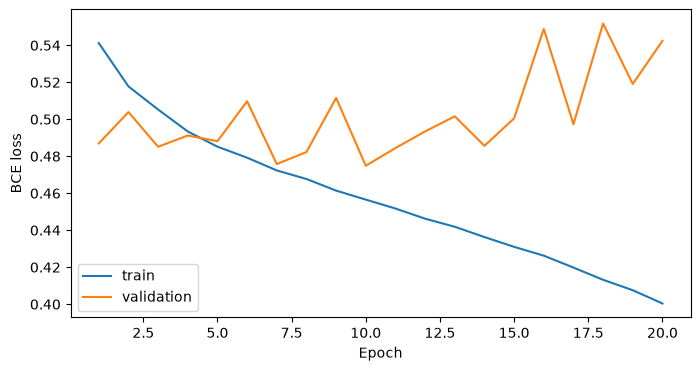

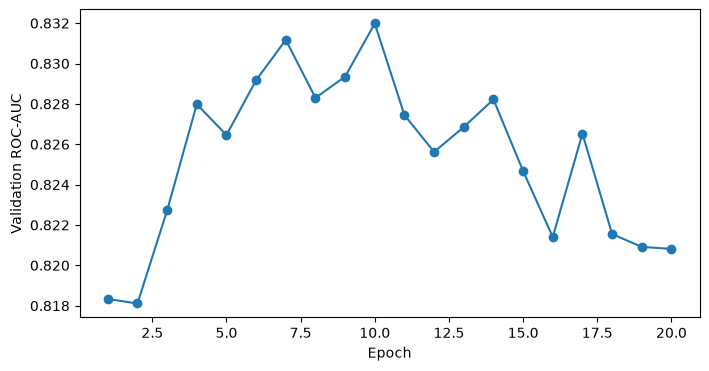

In [10]:
plt.figure(figsize=(8,4))
plt.plot(hist.epoch,hist.train_loss,label="train"); plt.plot(hist.epoch,hist.val_loss,label="validation")
plt.xlabel("Epoch"); plt.ylabel("BCE loss"); plt.legend(); plt.show()
plt.figure(figsize=(8,4)); plt.plot(hist.epoch,hist.val_auc,marker="o")
plt.xlabel("Epoch"); plt.ylabel("Validation ROC-AUC"); plt.show()

## 8. Test evaluation

Use the test split only after choosing the checkpoint on validation AUC. Threshold-dependent metrics below use a probability threshold of 0.5.

In [11]:
yt,yp,test_loss=predict(model,test_loader)
pred=(yp>=.5).astype(int)
tn,fp,fn,tp=confusion_matrix(yt,pred,labels=[0,1]).ravel()
metrics={
 "test_loss":test_loss,
 "ROC_AUC":roc_auc_score(yt,yp),
 "PR_AUC":average_precision_score(yt,yp),
 "Accuracy":accuracy_score(yt,pred),
 "Balanced_Accuracy":balanced_accuracy_score(yt,pred),
 "F1":f1_score(yt,pred,zero_division=0),
 "Sensitivity":tp/(tp+fn) if tp+fn else np.nan,
 "Specificity":tn/(tn+fp) if tn+fp else np.nan}
pd.Series(metrics)

test_loss            0.465195
ROC_AUC              0.839609
PR_AUC               0.807626
Accuracy             0.768100
Balanced_Accuracy    0.752882
F1                   0.704864
Sensitivity          0.650129
Specificity          0.855634
dtype: float64

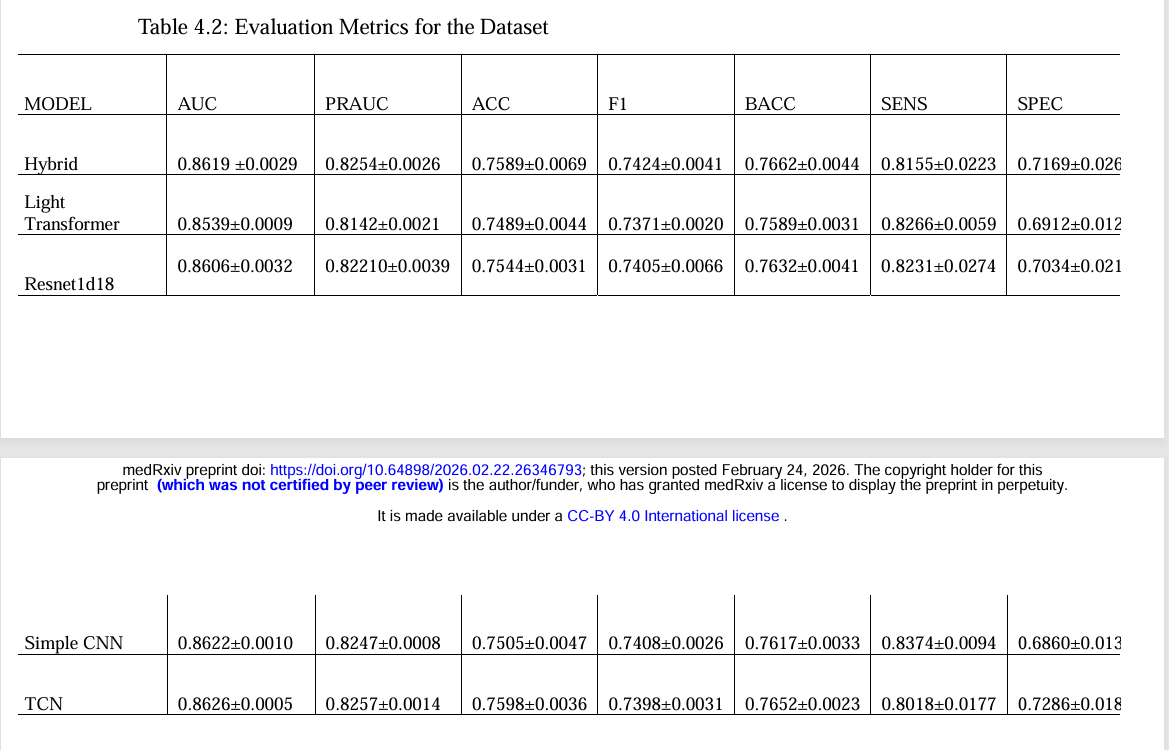

In [12]:
print(classification_report(yt,pred,target_names=["No SHD","SHD"],zero_division=0))
print("Confusion matrix [[TN,FP],[FN,TP]]:")
print(confusion_matrix(yt,pred,labels=[0,1]))

              precision    recall  f1-score   support

      No SHD       0.77      0.86      0.81      3124
         SHD       0.77      0.65      0.70      2318

    accuracy                           0.77      5442
   macro avg       0.77      0.75      0.76      5442
weighted avg       0.77      0.77      0.76      5442

Confusion matrix [[TN,FP],[FN,TP]]:
[[2673  451]
 [ 811 1507]]


## 9. Inspect learned modality weights

These are the gating network's learned weights for each example, not a validated clinical explanation.

Mean ECG weight: 0.5475344
Mean tabular weight: 0.45246562


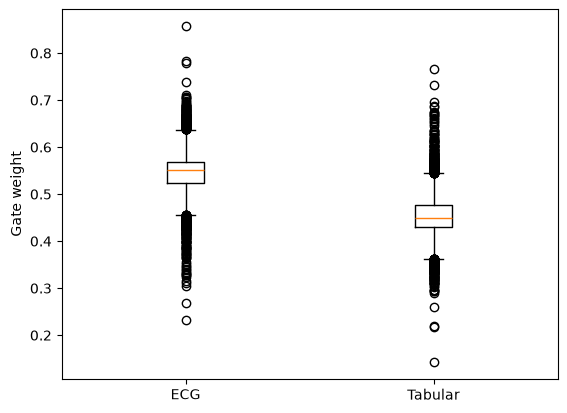

In [16]:
model.eval(); gates_all=[]
with torch.no_grad():
    for ecg,tab,y in test_loader:
        _,w=model(ecg.to(device),tab.to(device),return_gate=True)
        gates_all.append(w.cpu().numpy())
gates_all=np.concatenate(gates_all)
print("Mean ECG weight:",gates_all[:,0].mean())
print("Mean tabular weight:",gates_all[:,1].mean())
plt.boxplot([gates_all[:,0],gates_all[:,1]],tick_labels=["ECG","Tabular"])
plt.ylabel("Gate weight"); plt.show()

## 10. What is and is not reproduced

- Uses the official EchoNext train/validation/test splits and the distributed preprocessed waveform/tabular arrays.
- Uses the seven tabular inputs and composite `shd_moderate_or_greater_flag` label.
- Implements the paper's described two-encoder multimodal structure and adaptive gated late fusion.
- Implements a TCN ECG backbone and the paper's reported core training choices.
- TCN block widths, kernel size, embedding dimension, MLP widths, and gate widths are engineering choices because the paper does not fully specify them.
- This notebook implements the TCN version. The paper also compares Simple CNN-1D, ResNet1D-18, Light Transformer, and Hybrid; those baselines are not included here.
- For paper-style robustness, train from scratch with seeds 1, 2, and 3 and report mean ± standard deviation.
- The authors' paper is a preprint and states it has not been certified by peer review. Model predictions are not a medical diagnosis.

## References

1. Ajadi et al., *Multimodal Deep Learning for Structural Heart Disease Prediction from ECG and Clinical Data*, medRxiv (2026), https://doi.org/10.64898/2026.02.22.26346793
2. Elias & Finer, *EchoNext: A Dataset for Detecting Echocardiogram-Confirmed Structural Heart Disease from ECGs*, PhysioNet v1.1.1 (2026), https://doi.org/10.13026/7cfw-d091
3. Bai, Kolter & Koltun, *An Empirical Evaluation of Generic Convolutional and Recurrent Networks for Sequence Modeling* (2018), https://arxiv.org/abs/1803.01271